# Big Assignment

In this assignment, you will analyse **Swiss railway data**. Every day, several million passengers board and alight at roughly 1'800 railway stations in Switzerland. How busy a station is depends on its location, size, platforms and infrastructure operator. You will clean and combine three official open datasets published by the Swiss Federal Office of Transport on [opentransportdata.swiss](https://opentransportdata.swiss/), explore the data and build a model to predict how busy a station is. You do **not** need to visit the data source or obtain new data.

## Read this first

### Assignment structure

Work through the questions in order: they guide you through a complete data analysis workflow. Document your workflow in the `.ipynb` Markdown cells or code comments beginning with `#`. You may spread your code across several consecutive cells.

The assignment has **10 regular questions** and **one optional question (Question 11)**. Correct code and well-reasoned answers to Questions 1–10 can earn up to a **grade of 5.6**, or 80% of the way from a passing grade of 4 to the maximum grade of 6. It is perfectly fine to stop there.

Question 11 invites you to improve your previous models using your own ideas. Like a figure skating performance, it is assessed on technical quality, creativity and overall presentation. There is no single correct solution.



### Submission instructions

- Submit your completed `.ipynb` Notebook to **Canvas by 30 October 2026 at 20:00**, named `lastname_firstname_26.ipynb`. All code and solution comments are included in this single notebook.
- **Restart the kernel and run all cells in order** before submitting. In Jupyter/Nuvolos, select "Restart Kernel and Run All Cells" from the "Run" menu. Check that your code runs, the outputs are as expected and your answers address each question. Save the notebook with all cells and outputs included.
- **If you work outside Nuvolos**, run `pip list` and copy and paste its output into `requirements_lastname_firstname.txt`. Include your Python version in the same file and upload it to Canvas so that we can reproduce your results. Nuvolos users do not need to submit this file.

### Questions about the assignment

For content questions, check the Canvas discussion forum for the Big Assignment. If your question has not been asked, open a new thread. 
Content questions will only be answered there, to make it fair for everyone.

For technical issues (e.g. with Nuvolos), directly email Erik (erik-jan.senn@unisg.ch).

**Check the Canvas discussion forum regularly for updates and additional information.**

**Good luck!** 👩🏻‍💻🍀


## Package imports and optional installations

Load the packages and functions you need here.

If a required package is not installed, use `%pip install packagename` in Jupyter Notebook or `python -m pip install packagename` in a terminal. To specify a version, use `packagename==X.Y`.

You can return here later to add imports and installations.


In [1]:
# Your pip installs for new packages (optional, only if required)
# Notebook:
# %pip install pandas==2.2.3 numpy==2.1.3
# Terminal (shell):
# python -m pip install pandas==2.2.3 numpy==2.1.3

In [2]:
# Your package imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# add more package imports below as needed

## The data

<span style="color:red">Take your time to read this section carefully. Get back to it later when necessary.</span>

The three datasets are in the `data` subfolder next to this notebook:

1. `passengers.csv` contains, for a number of reference years, the **annual average of the daily number of passengers boarding and alighting** at each Swiss railway station, together with the station name, its canton and the infrastructure operator. This is the quantity we eventually want to predict. There is one observation per station-year.
2. `stations.csv` is the official Swiss **service point register**. It contains one row per *validity period* of a service point (station, stop, bus stop, ...), with its country, canton, district, municipality, elevation above sea level and coordinates.
3. `platforms.csv` contains one row per **platform** ("Perron") of a railway station: the platform type, its length in metres, its gross and net surface area in square metres, and whether it can be reached **without crossing the tracks**.

All three files are semicolon-separated (`;`) and contain non-ASCII characters (e.g. `Perron Länge`). Keep this in mind in Question 1.

Some column names combine German, French and Italian.

The table below describes the main columns used in the assignment:

| Column | Dataset | Meaning |
| --- | --- | --- |
| `UIC` | `passengers.csv` | international station identifier |
| `Bahnhof_Gare_Stazione` | `passengers.csv` | station name |
| `Kt_Ct_Cantone` | `passengers.csv` | canton |
| `ISB_GI` | `passengers.csv` | infrastructure operator (*Infrastrukturbetreiberin*) |
| `Jahr_Annee_Anno` | `passengers.csv` | reference year |
| `DTV_TJM_TGM` | `passengers.csv` | **average number of** daily **boardings + alightings** over one **year** |
| `DWV_TMJO_TFM` | `passengers.csv` | **average boardings + alightings on working days** over one **year** |
| `DNWV_TMJNO_TMGNL` | `passengers.csv` | **average boardings + alightings on non-working days** over one **year** |
| `number` | `stations.csv` | service point identifier (same numbering as `UIC`) |
| `isoCountryCode`, `cantonAbbreviation`, `municipalityName`, `fsoNumber` | `stations.csv` | country / canton / municipality (`fsoNumber` is the official municipality number) |
| `validFrom` | `stations.csv` | first day on which this version of the service-point record (e.g. for a railway station or bus stop) applies (`YYYY-MM-DD`). "Valid" refers to the station information, not to individual tickets :) |
| `validTo` | `stations.csv` | last day on which the information in this row applies. A "version" is a record containing information valid for a particular period. `9999-12-31` means no specified end date in the supplied file. "Valid" refers to the station information, not to individual tickets :) |
| `status` | `stations.csv` | stage in the validation/release process (e.g. `VALIDATED`); separate from the date-based validity period. "Valid" refers to the station information, not to individual tickets :) |
| `meansOfTransport` | `stations.csv` | which means of transport serve the point |
| `height`, `wgs84East`, `wgs84North` | `stations.csv` | elevation (m) and coordinates |
| `BPUIC` | `platforms.csv` | station identifier the platform belongs to |
| `Perrontyp` | `platforms.csv` | platform type |
| `Perron Länge` | `platforms.csv` | platform length (m) |
| `perronflach_brutto_m2` | `platforms.csv` | gross platform area (m²) |
| `schienenfreier Zugang` | `platforms.csv` | access without crossing the tracks (`ja` / `nein`) |

**If the meaning of some data columns is not fully clear to you yet, don't worry too much. Some columns may not be essential to the task, and you can return to their meaning later if needed.**

The register can contain several versions of the same service point. `validFrom` and `validTo` describe when the information in a row applies, rather than necessarily when the station opened or closed.

We use passenger counts for **2024** and station records valid on **31 December 2024**. `YEAR` and `REFERENCE_DATE` are fixed in the cell below. This selects the station records valid at year end; they do not need to have applied throughout the year.

In [3]:
YEAR = 2024   # reference year used throughout the assignment
REFERENCE_DATE = pd.Timestamp(f"{YEAR}-12-31")  # station snapshot at year end


## Part 1: Data preprocessing and plotting

### Question 1

Load the three datasets using a function named `read_and_info(filepath)` that:

- reads the file at `filepath` into a pandas DataFrame;
- prints the file path and the numbers of rows and columns with clear labels, then shows the first five rows (you may display only some columns);
- returns the DataFrame.

Call the function once per dataset and store the results in `passengers`, `stations` and `platforms`.

*Hints:* The files are **semicolon-separated**, so use the `sep` argument of `pd.read_csv`. Some files begin with a byte-order mark; `encoding='utf-8-sig'` removes it. If pandas warns about mixed types in the large service point register, use `low_memory=False`.


In [4]:
# Your solution
def read_and_info(filepath):
    # read dataframe with info from above
    df = pd.read_csv(filepath, sep=";", encoding="utf-8-sig", low_memory=False)

    # print file path and size of dataframe
    print(f"File: {filepath}")
    print(f"Number of rows: {df.shape[0]}, number of columns: {df.shape[1]}")

    # show first five rows
    display(df.head())

    return df

In [5]:
passengers = read_and_info("data/passengers.csv")
stations = read_and_info("data/stations.csv")
platforms = read_and_info("data/platforms.csv")

File: data/passengers.csv
Number of rows: 5724, number of columns: 16


,Code_Codice,UIC,Bahnhof_Gare_Stazione,Kt_Ct_Cantone,ISB_GI,Jahr_Annee_Anno,DTV_TJM_TGM,DWV_TMJO_TFM,DNWV_TMJNO_TMGNL,EVU_EF_ITF,Bemerkung,Bemerkungen,Note,Bemerkungen.1,lod,Geopos
0,AA,8502113.0,Aarau,AG,SBB,2018,37900.0,44800.0,22700.0,SBB,Ohne AVA.,Sans AVA.,Senza AVA.,Without AVA.,http://lod.opentransportdata.swiss/didok/didok85,"47.39135951416977, 8.051273718700699"
1,AA,8502113.0,Aarau,AG,SBB,2023,37700.0,43400.0,24700.0,"SBB, SOB",Ohne AVA.,Sans AVA.,Senza AVA.,Without AVA.,http://lod.opentransportdata.swiss/didok/didok85,"47.39135951416977, 8.051273718700699"
2,AA,8502113.0,Aarau,AG,SBB,2024,39000.0,45300.0,24800.0,"SBB, SOB",Ohne AVA.,Sans AVA.,Senza AVA.,Without AVA.,http://lod.opentransportdata.swiss/didok/didok85,"47.39135951416977, 8.051273718700699"
3,AA,8502113.0,Aarau,AG,SBB,2025,40100.0,46600.0,25700.0,"SBB, SOB",Ohne AVA.,Sans AVA.,Senza AVA.,Without AVA.,http://lod.opentransportdata.swiss/didok/didok85,"47.39135951416977, 8.051273718700699"
4,AAT,8503124.0,Aathal,ZH,SBB,2022,690.0,750.0,570.0,SBB,NaN,NaN,NaN,NaN,http://lod.opentransportdata.swiss/didok/didok85,"47.3359591338364, 8.765625135347072"


File: data/stations.csv
Number of rows: 157814, number of columns: 56


,numberShort,uicCountryCode,sloid,number,checkDigit,globalId,validFrom,validTo,designationOfficial,designationLong,...,businessOrganisationDescriptionEn,fotComment,lv95East,lv95North,wgs84East,wgs84North,height,creationDate,editionDate,status
0,22001,13,ch:1:sloid:1322001,1322001,2,NaN,2017-07-12,2020-08-31,Antronapiana,NaN,...,Autoservizi Comazzi S.R.L.,NaN,2652235.0,1101179.0,8.113620,46.060120,0.0,2020-08-31 11:27:18,2023-10-11 14:56:52,VALIDATED
1,22001,13,ch:1:sloid:1322001,1322001,2,NaN,2020-09-01,9999-12-31,Antronapiana,NaN,...,Autoservizi Comazzi S.R.L.,NaN,2652235.0,1101179.0,8.113620,46.060120,0.0,2017-11-09 11:53:05,2024-04-08 09:26:05,VALIDATED
2,22002,13,ch:1:sloid:1322002,1322002,0,NaN,2017-07-12,2020-08-31,Anzola,NaN,...,Dummy_Bez_EN,NaN,2670286.0,1093551.0,8.345715,45.989869,0.0,2020-08-31 11:27:18,2023-10-11 14:56:52,VALIDATED
3,22002,13,ch:1:sloid:1322002,1322002,0,NaN,2020-09-01,2021-04-29,Anzola,NaN,...,Dummy_Bez_EN,NaN,2670286.0,1093551.0,8.345715,45.989869,0.0,2021-04-30 11:55:31,2023-10-11 14:56:52,VALIDATED
4,22002,13,ch:1:sloid:1322002,1322002,0,NaN,2021-04-30,2023-02-22,Anzola,NaN,...,Autoservizi Comazzi S.R.L.,NaN,2670286.0,1093551.0,8.345715,45.989869,0.0,2023-02-23 13:56:18,2023-10-11 14:56:52,VALIDATED


File: data/platforms.csv
Number of rows: 1570, number of columns: 16


,Linie,KM,Abkuerzung Bahnhof,Haltestellen Name,Perrontyp,Perron Nummer,Perron Länge,perronflach_brutto_m2,perronflach_netto_m2,schienenfreier Zugang,Didok-Nummer,DOK_PFM,FID,Geoposition,BPUIC,lod
0,930,-0.188,CH,Chur,Hausperron,2,238.0,1055,NaN,ja,9000,Ost,35298908,"46.85410522379755, 9.530767756523879",8509000,http://lod.opentransportdata.swiss/didok/8509000
1,930,-0.182,CH,Chur,Aussenperron,1,254.0,726,NaN,ja,9000,Ost,35298924,"46.85399535489746, 9.53084429859494",8509000,http://lod.opentransportdata.swiss/didok/8509000
2,920,13.447,CH,Chur,Mittelperron,9/10,533.0,4300,3740.31,ja,9000,Ost,35297017,"46.85482367993608, 9.530824499892729",8509000,http://lod.opentransportdata.swiss/didok/8509000
3,920,13.543,CH,Chur,Mittelperron,11/12,382.0,2466,2081.40,ja,9000,Ost,35297030,"46.85436824080668, 9.529733935852612",8509000,http://lod.opentransportdata.swiss/didok/8509000
4,920,13.646,CH,Chur,Mittelperron,13/14,181.0,1156,896.22,ja,9000,Ost,35302702,"46.853906520689506, 9.528536006606826",8509000,http://lod.opentransportdata.swiss/didok/8509000


### Question 2

Each column in your DataFrames should have an appropriate **data type**. Incorrect or inconsistent data types can lead to errors or misleading results.

We will use the following standard data types:

- Integer → `'Int64'`
- Float → `'float64'` or `'Float64'` (pandas' nullable type)
- String → `'string'`
- Date/time → `'datetime64[s]'`
- Boolean → `'boolean'`

For `validFrom` and `validTo`, use `datetime64[s]` (second precision). This can represent the open-ended date `9999-12-31`, which is outside the range of `datetime64[ns]`. Convert these columns with `.astype("datetime64[s]")`; the other columns can use the same conversion loop.

In the passenger-count variables, a recorded value of `49` means “fewer than 50 daily boarding and alighting movements”; it is not an exact count. For this assignment, retain these values and use `49` in all calculations and models. This is a simplifying approximation. (If you are curious, we can discuss this issue next week: we have a so-called “left-censored” outcome variable.)

**Your tasks:**

1. **Reduce each dataset to the columns you actually need.** The files contain many columns that this analysis does not need; the service point register alone has 56. Keeping only relevant columns makes the analysis easier to follow.

   Decide which columns to keep in `passengers`, `stations` and `platforms`. Start with the table in the introduction, then check Questions 3–5 for any additional columns needed to identify records, link the datasets or filter the data.

   Overwrite `passengers`, `stations` and `platforms` with the reduced DataFrames, print the shape of each one before and after, and briefly justify any column you keep that is not in the introduction table.

   *If you later need a dropped column, reload the data and revise your selection.*

2. **Inspect and reflect.** For each of the three reduced datasets, look at the remaining columns and decide what the *appropriate* data type for each one should be.
   - Think about what each variable represents (e.g. identifiers, counts, lengths, areas, names, dates).
   - Provide one example where a column's *inferred* type from pandas is *not* the correct one. (Do not use `UIC` as an example.)

   Only document the one incorrectly inferred type in your submission; keep personal notes on the rest.

3. **Explain.** By default, pandas reads the column `UIC` as a number, and you *could* leave it that way. In two or three sentences, explain why a station identifier should **not** be treated as a numerical measurement, and what would go wrong later if you did.

4. **Define your schema.** Create a Python dictionary named `desired_dtypes` that maps each remaining column name to its intended data type.
   *(Example: `{'UIC': 'Int64', 'DTV_TJM_TGM': 'Float64', 'Bahnhof_Gare_Stazione': 'string'}`)*

5. **Apply conversions.** Convert the columns in each DataFrame to their desired types, e.g. using a loop.

6. **Careful with the identifier.** `UIC` is currently stored as a float, so the station Aarau appears as `8502113.0`. Convert the identifier so that **no trailing `.0`** remains in the printed output. Print five values of the converted column to show that it worked.

7. **Verify and print results.** Display the `.dtypes` of each DataFrame before and after conversion to confirm your changes.

**Revisiting this task**

Work through the questions in order, but be prepared to revisit your choices in this question. For example, a later task may require a column that you dropped here.

This is an intended part of the assignment. Return to Question 2 and revise your code. Then restart the kernel and run the notebook from the beginning up to the question you were working on. Check that the revised workflow works as intended before continuing.

FID is the unique identifier of each platform. Question 3 asks for the number of duplicated platform identifiers, and BPUIC can't do that because it identifies the station, not the platform. A station has several platforms, so the same BPUIC appears many times. We therefore keep FID aswell

In [6]:
# Your solution

# Task 1
# columns to keep (see justification above)
passengers_cols = ["UIC", "Bahnhof_Gare_Stazione", "Kt_Ct_Cantone", "ISB_GI",
                   "Jahr_Annee_Anno", "DTV_TJM_TGM", "DWV_TMJO_TFM", "DNWV_TMJNO_TMGNL"]
stations_cols = ["number", "isoCountryCode", "municipalityName", "fsoNumber",
                 "validFrom", "validTo", "status", "meansOfTransport",
                 "height", "wgs84East", "wgs84North"]
platforms_cols = ["FID", "BPUIC", "Perrontyp", "Perron Länge",
                  "perronflach_brutto_m2", "schienenfreier Zugang"]

# Print shapes before, reduce, print shapes after
print("Before:", passengers.shape, stations.shape, platforms.shape)
passengers = passengers[passengers_cols]
stations = stations[stations_cols]
platforms = platforms[platforms_cols]
print("After: ", passengers.shape, stations.shape, platforms.shape)



Before: (5724, 16) (157814, 56) (1570, 16)
After:  (5724, 8) (157814, 11) (1570, 6)


In [7]:
#Task 2 & part of 7
# dtypes before conversion
for df in [passengers, stations, platforms]:
    print(df.dtypes, "\n")
    print(df.head())

UIC                      float64
Bahnhof_Gare_Stazione     object
Kt_Ct_Cantone             object
ISB_GI                    object
Jahr_Annee_Anno            int64
DTV_TJM_TGM              float64
DWV_TMJO_TFM             float64
DNWV_TMJNO_TMGNL         float64
dtype: object 

         UIC Bahnhof_Gare_Stazione Kt_Ct_Cantone ISB_GI  Jahr_Annee_Anno  \
0  8502113.0                 Aarau            AG    SBB             2018   
1  8502113.0                 Aarau            AG    SBB             2023   
2  8502113.0                 Aarau            AG    SBB             2024   
3  8502113.0                 Aarau            AG    SBB             2025   
4  8503124.0                Aathal            ZH    SBB             2022   

   DTV_TJM_TGM  DWV_TMJO_TFM  DNWV_TMJNO_TMGNL  
0      37900.0       44800.0           22700.0  
1      37700.0       43400.0           24700.0  
2      39000.0       45300.0           24800.0  
3      40100.0       46600.0           25700.0  
4        690.0    

In [8]:
#Task 4, 5, 6 and part of 7

desired_dtypes = {
    # passengers
    "UIC": "string",
    "Bahnhof_Gare_Stazione": "string",
    "Kt_Ct_Cantone": "string",
    "ISB_GI": "string",
    "Jahr_Annee_Anno": "Int64",
    "DTV_TJM_TGM": "Int64",
    "DWV_TMJO_TFM": "Int64",
    "DNWV_TMJNO_TMGNL": "Int64",
    # stations
    "number": "string",
    "isoCountryCode": "string",
    "municipalityName": "string",
    "fsoNumber": "string",
    "validFrom": "datetime64[s]",
    "validTo": "datetime64[s]",
    "status": "string",
    "meansOfTransport": "string",
    "height": "Float64",
    "wgs84East": "Float64",
    "wgs84North": "Float64",
    # platforms
    "FID": "string",
    "BPUIC": "string",
    "Perrontyp": "string",
    "Perron Länge": "Float64",
    "perronflach_brutto_m2": "Float64",
    "schienenfreier Zugang": "string",
}

# float identifiers first go to int, so no trailing .0 appears in the strings
passengers["UIC"] = passengers["UIC"].astype("Int64")
stations["fsoNumber"] = stations["fsoNumber"].astype("Int64")

# convert every column to my desired type
for df in [passengers, stations, platforms]:
    for col in df.columns:
        df[col] = df[col].astype(desired_dtypes[col])
    
# dtypes after conversion and a check of the identifier
for df in [passengers, stations, platforms]:
    print(df.dtypes, "\n")
print(passengers["UIC"].head())

UIC                      string[python]
Bahnhof_Gare_Stazione    string[python]
Kt_Ct_Cantone            string[python]
ISB_GI                   string[python]
Jahr_Annee_Anno                   Int64
DTV_TJM_TGM                       Int64
DWV_TMJO_TFM                      Int64
DNWV_TMJNO_TMGNL                  Int64
dtype: object 

number              string[python]
isoCountryCode      string[python]
municipalityName    string[python]
fsoNumber           string[python]
validFrom            datetime64[s]
validTo              datetime64[s]
status              string[python]
meansOfTransport    string[python]
height                     Float64
wgs84East                  Float64
wgs84North                 Float64
dtype: object 

FID                      string[python]
BPUIC                    string[python]
Perrontyp                string[python]
Perron Länge                    Float64
perronflach_brutto_m2           Float64
schienenfreier Zugang    string[python]
dtype: object 

0    85

Part of task 2

An example for an incorrectly inferred type is the column validFrom that I changed from object to a datetime64[s] since pandas read it as object because it does not recognise dates automatically I think but it is a date

Task 3:

UIC should not be treated as a numerical measurement since the number does not relate to any fact. It does not matter whether the UIC of one station is higher or lower, it's just there to refer to the station, e.g. a UIC of 8502113 is not twice as busy or twice as large as one of 4251056, and the average of two UICs means nothing. The model could infer a linear relationship between the numerical codes even though there is no logical reason to do so.

### Question 3

Before aggregating and merging the DataFrames, **clean each dataset separately**. Data cleaning includes removing unsuitable rows or columns and correcting how values are represented. The instructions are intentionally open: make and justify decisions appropriate for this analysis.

1. **Diagnose.** For each DataFrame, print a concise summary of
   - the number of **missing values** per column,
   - the number of **duplicated identifiers** (`UIC` within the reference year, `number`, and the platform identifier),
   - **implausible measurements** — think about what a platform of length 0 m, or an area of 0 m², would mean.

2. **Restrict the data to what the question is about.** In particular:
   - `passengers.csv`: Keep only rows for the reference year (`YEAR = 2024`), using the year column in `passengers`, and keep only **Swiss** stations (the canton column contains a value for stations abroad);
   - `stations.csv`: The service point register contains every bus stop, boat landing and cable car station in the country. It also contains **historical** records and records that may not yet be validated (see the column `status` in `stations.csv`). Keep only the rows that describe a **validated Swiss service point served by trains and valid on 31 December 2024** (`REFERENCE_DATE = pd.Timestamp(f"{YEAR}-12-31")`). Apply the date filter explained below (under *validity dates*) together with `status`, `isoCountryCode` and `meansOfTransport`. After this step the identifier `number` must be **unique**. Verify this explicitly; do not resolve repeated identifiers by arbitrarily dropping rows.

     *Validity dates:* Select records whose validity period includes `REFERENCE_DATE`: `validFrom <= REFERENCE_DATE <= validTo` (including both endpoints). Checking only whether `validTo` is `9999-12-31` is insufficient: an open-ended record may start after the reference date, while a record with a finite end date may still apply on that date. For more detailed documentation, see the column definitions in [The data](#The-data) and the [official service-point documentation](https://opentransportdata.swiss/en/cookbook/masterdata-cookbook/servicepoints/).

   - `platforms.csv`: The platform register contains platform types that are not open to passengers (look at the values of `Perrontyp` — some of them are for staff/operations only). Keep only **public passenger platforms**.

3. **Handle any remaining problems** and document your choices. A **missing measurement must not silently become a 0**. For example, a platform whose length was never recorded is not a platform of length zero. Explain how you treat such cases.

4. Print the shape of each DataFrame before and after cleaning.

*Note:* You may need to revisit your cleaning decisions later. Adjust the relevant code, then rerun the notebook from the beginning before continuing. Revising earlier steps is normal in data analysis.

In [9]:
# Your solution
#Task 1
# missing values per column
for df in [passengers, stations, platforms]:
    missing = df.isna().sum()
    print(missing[missing > 0], "\n")

# duplicated identifiers
print("passengers, UIC within 2024:", passengers.loc[passengers["Jahr_Annee_Anno"] == YEAR, "UIC"].duplicated().sum())
print("stations, number:", stations["number"].duplicated().sum())
print("platforms, FID:", platforms["FID"].duplicated().sum())

# implausible measurements
print("platforms with length <= 0:", (platforms["Perron Länge"] <= 0).sum()) #boolean sum for all
print("platforms with gross area <= 0:", (platforms["perronflach_brutto_m2"] <= 0).sum())
print("passengers with DTV <= 0:", (passengers["DTV_TJM_TGM"] <= 0).sum())

Series([], dtype: int64) 

isoCountryCode      24345
municipalityName    59845
fsoNumber           59845
meansOfTransport    28824
height              27231
wgs84East           24313
wgs84North          24313
dtype: int64 

Perron Länge             7
schienenfreier Zugang    6
dtype: int64 

passengers, UIC within 2024: 0
stations, number: 84655
platforms, FID: 0
platforms with length <= 0: 0
platforms with gross area <= 0: 1
passengers with DTV <= 0: 0


the 84'655 duplicated numbers in stations are not errors -> the register has one row per validity period of a service point, so the same number appears several times and this is why i filter by date in task 2. a platform with a length or area of 0 m cannot exist, so a 0 is a data error (most likely a missing value stored as 0) and not a real measurement. there is one platform with a gross area of 0 and no platform with a length of 0.

In [10]:
#part of task 4
print("Before:", passengers.shape, stations.shape, platforms.shape)

Before: (5724, 8) (157814, 11) (1570, 6)


In [11]:
#Task 2
# passengers: reference year, then swiss stations only
passengers = passengers[passengers["Jahr_Annee_Anno"] == YEAR]
passengers = passengers[passengers["Kt_Ct_Cantone"] != "Ausland"]

# stations: validated, swiss, served by trains, valid on the reference date
stations = stations[
    (stations["validFrom"] <= REFERENCE_DATE)
    & (REFERENCE_DATE <= stations["validTo"])
    & (stations["status"] == "VALIDATED")
    & (stations["isoCountryCode"] == "CH")
    & (stations["meansOfTransport"].str.contains("TRAIN", na=False))
]

# number must now be unique so check
print("stations, duplicated number:", stations["number"].duplicated().sum())

# platforms: drop staff/operations-only platform types (which I think is Dienstperron and Hilfskante)
platforms = platforms[~platforms["Perrontyp"].isin(["Dienstperron", "Hilfskante"])] #helped by claude for this one

stations, duplicated number: 0


In [12]:
#Task 3 & 4
# platforms: ja/nein -> True/False, missing should stay <NA> (not turned into false)
"""
dropping the staff platforms removed the only platform with 0 m2 area. 
6 platforms have no recorded length and 6 have no schienenfreier zugang.
I keep these as missing (<NA>) instead of 0, because an unrecorded value
is not a length of zero. the aggregation in q4 ignores them.
"""

platforms["schienenfreier Zugang"] = (
    platforms["schienenfreier Zugang"].map({"ja": True, "nein": False}).astype("boolean")
) #code corrected with help from claude

# check: no length or area of 0 (missing values are kept as <NA>, not 0)
print("length <= 0:", (platforms["Perron Länge"] <= 0).sum())
print("area <= 0:", (platforms["perronflach_brutto_m2"] <= 0).sum())

# remaining missing values and final shapes
for df in [passengers, stations, platforms]:
    print(df.shape)
    missing = df.isna().sum()
    print(missing[missing > 0], "\n")

print("After:", passengers.shape, stations.shape, platforms.shape)

length <= 0: 0
area <= 0: 0
(1153, 8)
Series([], dtype: int64) 

(1713, 11)
Series([], dtype: int64) 

(1439, 6)
Perron Länge             6
schienenfreier Zugang    6
dtype: int64 

After: (1153, 8) (1713, 11) (1439, 6)


/tmp/ipykernel_48095/848804694.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  platforms["schienenfreier Zugang"] = (


### Question 4

The platform register has **one row per platform**, but we want to describe **stations**. Aggregate the platform data to the station level.

Build a DataFrame named `platform_stats` with **one row per station identifier** (`BPUIC`) and exactly the following columns:

| Column | Content |
| --- | --- |
| `n_platforms` | number of platforms at the station |
| `platform_length_total` | total platform length in metres |
| `platform_length_mean` | mean platform length in metres |
| `platform_area_total` | total **gross** platform area in m² |
| `share_track_free` | proportion of the station's platforms that can be reached **without crossing the tracks** |

Note that `share_track_free` must be a number between 0 and 1, not a count and not a percentage string.

Print the shape of `platform_stats`, its first few rows and the `.describe()` summary of the five columns. Briefly comment on whether the numbers look plausible for Swiss railway stations.

In [13]:
# Your solution
# one row per station
platform_stats = platforms.groupby("BPUIC").agg( #claude came up with the .agg solution
    n_platforms=("FID", "count"),                        # number of platforms
    platform_length_total=("Perron Länge", "sum"),       # total length
    platform_length_mean=("Perron Länge", "mean"),       # mean length
    platform_area_total=("perronflach_brutto_m2", "sum"),  # total gross area
    share_track_free=("schienenfreier Zugang", "mean"),  # mean of True/False = share (0 to 1)
).reset_index()  # to reset index obviosly so BPUIC becomes a normal column again

# shape, first rows and summary
print("Shape:", platform_stats.shape)
display(platform_stats.head())
display(platform_stats.drop(columns="BPUIC").describe())



Shape: (802, 6)


,BPUIC,n_platforms,platform_length_total,platform_length_mean,platform_area_total,share_track_free
0,8500010,12,5251.0,437.583333,39729.0,1.0
1,8500016,1,199.0,199.0,1472.0,1.0
2,8500020,3,662.0,220.666667,4367.0,1.0
3,8500021,3,804.0,268.0,4048.0,1.0
4,8500022,2,447.0,223.5,1975.0,1.0


,n_platforms,platform_length_total,platform_length_mean,platform_area_total,share_track_free
count,802.000000,802.0,802.0,802.0,802.0
mean,1.794264,422.074813,217.672389,2057.107232,0.948878
std,0.944829,399.395147,89.645696,2872.802764,0.19818
min,1.000000,19.0,19.0,39.0,0.0
25%,1.000000,177.75,150.5,670.75,1.0
50%,2.000000,324.0,199.25,1360.5,1.0
75%,2.000000,469.0,287.5,2152.75,1.0
max,12.000000,5251.0,653.5,39729.0,1.0


Most stations are small, with 1 to 2 platforms (mean about 1.8, median 2, maximum 12 at the largest stations). Most stations have fully track-free access (median share 1), and the mean share is about 0.95 which makes sense since only in the country you have those weird track accesses. Also platform lengths around 150 to 300 m fit Swiss trains and fit my experience. Platform area is difficult to access but makes sense if I had to guess.

### Question 5

Now merge the cleaned datasets into a single DataFrame. Use the cleaned versions from Question 3, whether you overwrote the original names or created new ones such as `pas` and `sta`.

1. **Check the merge keys first.** Identify the keys linking the three tables. Before each merge, print whether the relevant key is unique in each input and verify that it is. The keys have different names but refer to the same station.
2. **Count unmatched stations before merging.** Print how many stations in the cleaned passenger data have no match in the cleaned service point register and how many have no match in `platform_stats`. State in one sentence what kind of stations these are likely to be.
3. **Merge.** Combine the cleaned passenger data, the cleaned service point register and `platform_stats` into a DataFrame named `master`. Carry over at least `municipalityName`, `height`, `wgs84East` and `wgs84North` from the service point register. Use the type of merge that keeps only stations for which **all three** sources provide information, and justify this choice in one or two sentences.
4. **Check the result.** Print the shape of `master`, a short preview of its first rows, and the number of missing values in each column. Verify that it contains **exactly one row per station**.

In [14]:
# Your solution

# 1 
# I looked into the csv's by excel, the keys are UIC (passengers) = number (stations) = BPUIC (platform_stats) and all are strings
print("UIC unique in passengers:     ", passengers["UIC"].is_unique)
print("number unique in stations:    ", stations["number"].is_unique)
print("BPUIC unique in platform_stats:", platform_stats["BPUIC"].is_unique)

UIC unique in passengers:      True
number unique in stations:     True
BPUIC unique in platform_stats: True


In [15]:
# 2
# unmatched stations: passenger stations whose key is not in the other table
print("No match in stations:      ", (~passengers["UIC"].isin(stations["number"])).sum())
print("No match in platform_stats:", (~passengers["UIC"].isin(platform_stats["BPUIC"])).sum()) #codes were corrected by claude

No match in stations:       18
No match in platform_stats: 405


I looked into the csv via Excel. The 18 stations missing from the register are small, mostly Vaud mountain stops such as Glion, Caux, valmont etc. They are probably served only by rack railways or other things, which my TRAIN filter excluded. The 405 stations without platform data are likely stops of operators that are not covered by the platform register

In [16]:
# 3
# inner merges keep only stations present in all three sources
# only the columns we need from stations are carried over
station_cols = ["number", "municipalityName", "fsoNumber", "height", "wgs84East", "wgs84North"]
master = (
    passengers
    .merge(stations[station_cols], left_on="UIC", right_on="number", how="inner")
    .merge(platform_stats, left_on="UIC", right_on="BPUIC", how="inner")
    .drop(columns=["number", "BPUIC"])  # duplicate key columns, no longer needed
)

We need all features (location, platform data) to build the model. An inner merge keeps only stations with information from all three sources, so master has no missing feature values. A left merge would keep more stations but with missing platform values, which we would have to fill in

In [17]:

# 4
# check result
print("Shape:", master.shape)
display(master.head())
print(master.isna().sum())
print("One row per station:", master["UIC"].is_unique)

Shape: (746, 18)


,UIC,Bahnhof_Gare_Stazione,Kt_Ct_Cantone,ISB_GI,Jahr_Annee_Anno,DTV_TJM_TGM,DWV_TMJO_TFM,DNWV_TMJNO_TMGNL,municipalityName,fsoNumber,height,wgs84East,wgs84North,n_platforms,platform_length_total,platform_length_mean,platform_area_total,share_track_free
0,8502113,Aarau,AG,SBB,2024,39000,45300,24800,Aarau,4001,383.0,8.051274,47.39136,4,1822.0,455.5,11443.0,1.0
1,8502224,Affoltern am Albis,ZH,SBB,2024,7200,8300,4700,Affoltern am Albis,2,494.0,8.446595,47.27607,2,642.0,321.0,2747.0,1.0
2,8505201,Airolo,TI,SBB,2024,530,500,610,Airolo,5061,1142.0,8.60862,46.527526,2,554.0,277.0,3017.0,1.0
3,8501400,Aigle,VD,SBB,2024,11200,11900,9400,Aigle,5401,403.908,6.963683,46.316855,5,775.0,387.5,5586.0,1.0
4,8501035,Allaman,VD,SBB,2024,5200,6200,3100,Allaman,5851,421.868,6.399697,46.475754,2,565.0,282.5,3014.0,1.0


UIC                      0
Bahnhof_Gare_Stazione    0
Kt_Ct_Cantone            0
ISB_GI                   0
Jahr_Annee_Anno          0
DTV_TJM_TGM              0
DWV_TMJO_TFM             0
DNWV_TMJNO_TMGNL         0
municipalityName         0
fsoNumber                0
height                   0
wgs84East                0
wgs84North               0
n_platforms              0
platform_length_total    0
platform_length_mean     0
platform_area_total      0
share_track_free         0
dtype: int64
One row per station: True


### Question 6

Now take a closer look at the data:

1. **Distribution of the target.** Plot a histogram of the average daily passenger count `DTV_TJM_TGM`. Then produce a second histogram of the same variable on a **logarithmic x-axis**, using bins equally spaced on the logarithmic scale. Explain in one or two sentences what the first plot hides and why the logarithmic version is the more informative one for this variable.
2. **Size versus demand.** Produce a scatterplot with `platform_area_total` on the x-axis and `DTV_TJM_TGM` on the y-axis. Use logarithmic scales where you find it appropriate and justify your choice. Label both axes (including units) and give the plot a concise, descriptive title.

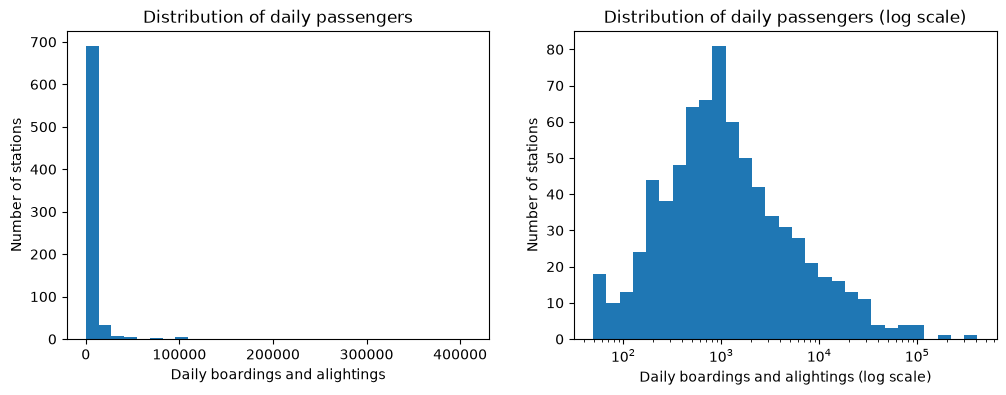

In [18]:
# Your solution
# 1
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# left: raw counts, linear x-axis
ax[0].hist(master["DTV_TJM_TGM"], bins=30)
ax[0].set_xlabel("Daily boardings and alightings")
ax[0].set_ylabel("Number of stations")
ax[0].set_title("Distribution of daily passengers")

# right: bins equally spaced on the log scale, log x-axis, I just used 30 bins but you could choose whatever
log_bins = np.logspace(np.log10(master["DTV_TJM_TGM"].min()),
                       np.log10(master["DTV_TJM_TGM"].max()), 30) #with the help of claude
ax[1].hist(master["DTV_TJM_TGM"], bins=log_bins)
ax[1].set_xscale("log")
ax[1].set_xlabel("Daily boardings and alightings (log scale)")
ax[1].set_ylabel("Number of stations")
ax[1].set_title("Distribution of daily passengers (log scale)")

plt.show()


The first plot is dominated by a huge spike of small stations at the left and a few very busy stations far to the right (like the one in the bigger cities), so the shape of the bulk of the stations is not very "seeable". On the log scale the distribution spreads out and looks roughly symmetric (bell-shaped), which shows the typical station and makes it easier to model.

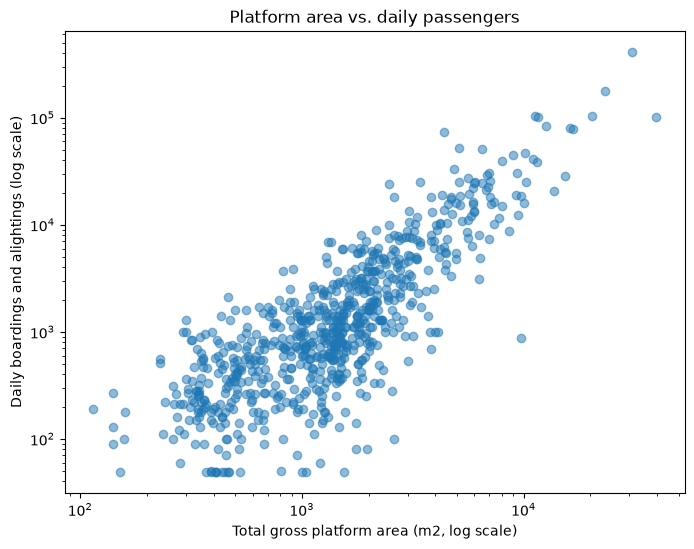

In [19]:
fig, ax = plt.subplots(figsize=(8, 6))

ax.scatter(master["platform_area_total"], master["DTV_TJM_TGM"], alpha=0.5)
ax.set_xscale("log")   # both variables are skewed and span several orders of magnitude, I tried both but log looks the best honestly which spreads out the points and shows the relationship clearer
ax.set_yscale("log")
ax.set_xlabel("Total gross platform area (m2, log scale)")
ax.set_ylabel("Daily boardings and alightings (log scale)")
ax.set_title("Platform area vs. daily passengers")

plt.show()

## Part 2: Machine learning

### Question 7

Prepare the data to predict how busy a station is from its physical and geographical characteristics.

If you dropped a column needed here, revisit your selection in Question 2 and rerun the notebook from the beginning.

1. **Define the target.** Create a column `y` in `master` given by

   $$y = \log\left(\texttt{DTV\_TJM\_TGM}\right).$$

   Use the **natural logarithm** (`np.log`).

   Refer to your histograms from Question 6 and explain in two or three sentences why modelling the logarithm could be more appropriate than modelling the raw count. State explicitly what has to be true of `DTV_TJM_TGM` for the logarithm to be defined, and verify that it holds in your data.

   As specified in Question 2, use the published numeric values, including `49`, when taking logarithms and evaluating models. The positivity check applies to these published values, not to the unknown actual counts below 50. No specialised treatment of censoring is required.

2. **Choose your features.** List the variables you include and briefly explain for each why it might help to predict `y`.

3. **Justify your exclusions.** List the variables you exclude. Discuss why you should exclude at least the following two groups of variables and what would happen if you included them.
   - Group 1: `DWV_TMJO_TFM` and `DNWV_TMJNO_TMGNL`, the working-day and non-working-day passenger counts;
   - Group 2: station names and identifiers.

4. Drop the excluded columns and name the resulting DataFrame `master_ml`. Print its shape and its columns.

In [20]:
# check again that there is no value =< 0
print(master["DTV_TJM_TGM"].min())

49


In [21]:
# Your solution
# 1
master["y"] = np.log(master["DTV_TJM_TGM"])

the histograms in question 6 show that the raw counts are very right-skewed so most stations are small and a few are huge, so a model on the raw scale would be dominated by the few big stations. on the log scale the distribution is roughly symmetric and effects become proportional. the logarithm is only defined for values strictly greater than 0 so DTV_TJM_TGM must be positive for every station

In [22]:
# overview built with claude to help decide
overview = pd.DataFrame({
    "dtype": master.dtypes,
    "n_unique": master.nunique(),
    "example": master.iloc[0],
})
display(overview)

,dtype,n_unique,example
UIC,string[python],746,8502113
Bahnhof_Gare_Stazione,string[python],746,Aarau
Kt_Ct_Cantone,string[python],22,AG
ISB_GI,string[python],2,SBB
Jahr_Annee_Anno,Int64,1,2024
DTV_TJM_TGM,Int64,228,39000
DWV_TMJO_TFM,Int64,239,45300
DNWV_TMJNO_TMGNL,Int64,204,24800
municipalityName,string[python],538,Aarau
fsoNumber,string[python],538,4001


Task 2

Kt_Ct_Cantone: captures regional differences which could differ e.g. cities, tourist regions

ISB_GI: infrastructure operator and operators differ in network type and in the stations they run which could impact traffic

height: I guess high-altitude stations tend to be quieter in traffic

wgs84East, wgs84North: location matters e.g. cities and the central plateau are busier than remote valleys

n_platforms: a direct measure of station size and traffic

platform_length_total: larger stations handle longer and more trains therefore more traffic

platform_area_total: a measure of the space available for passengers and it showed a strong relation to demand in the plot above in q6

share_track_free: a proxy for infrastructure quality and accessibility, you also only find those tracks in the lower populated areas from my experience

Task 3

Excluded: DTV_TJM_TGM (the target itself that I replaced with y), DWV_TMJO_TFM, DNWV_TMJNO_TMGNL, UIC, Bahnhof_Gare_Stazione, Jahr_Annee_Anno, municipalityName, fsoNumber and platform_length_mean.

Group 1: these are the working-day and non-working-day counts. The yearly average is almost a weighted mix of these two values (roughly 5/7 working days plus 2/7 non-working days I imagine). They contain the answer, so a model using them would look almost perfect without learning what makes a station busy (which would be target leakage if I remember correctly from yesterday). They would also not be available for a new station which is what we want to predict.

Group 2: station names and identifiers. Each station has a unique name and ID, so dummy coding would create one column per station, more columns than there are training rows. The model could memorise every training station and fit the training data perfectly but could not predict any new station, whose name it has never seen. A numeric ID would also be treated as a quantity which is meaningless.

Other exclusions that I took:

Jahr_Annee_Anno is 2024 for every row the same so it carries no information. 

municipalityName and fsoNumber identify the municipality and hundreds of values with mostly one station each would overfit I can imagine and test municipalities would often be unseen. 

platform_length_mean is derived from the total length and the number of platforms so it does not add any value

In [23]:
# 4
# drop the excluded columns expect y stays in as the target
excluded = ["UIC", "Bahnhof_Gare_Stazione", "Jahr_Annee_Anno",
            "DTV_TJM_TGM", "DWV_TMJO_TFM", "DNWV_TMJNO_TMGNL",
            "municipalityName", "fsoNumber", "platform_length_mean"]

master_ml = master.drop(columns=excluded)

print("Shape:", master_ml.shape)
print("Columns:", (master_ml.columns))


Shape: (746, 10)
Columns: Index(['Kt_Ct_Cantone', 'ISB_GI', 'height', 'wgs84East', 'wgs84North',
       'n_platforms', 'platform_length_total', 'platform_area_total',
       'share_track_free', 'y'],
      dtype='object')


### Question 8

Turn `master_ml` into a numeric feature matrix.

1. **Split first.** Split your data into a training set (70%) and a test set (30%) using a suitable function from scikit-learn with `random_state=42`. Do this **before** encoding and scaling.

2. **Identify categorical variables.** Inspect your features and list explicitly which ones are categorical (they contain labels rather than measurements).

3. **Encode categorical variables.** Convert them into dummy variables. Avoid **redundant dummy variables** so that the coefficients of a linear model with an intercept have a clear interpretation relative to a reference category. Make sure the training and test matrices end up with **the same columns in the same order**, also when a rare category happens to appear in only one of the two sets.

   *Hint*: Fit a single `OneHotEncoder` on the training categories, then use that fitted encoder to transform both sets. For example, `drop="first"` selects a reference category and `handle_unknown="ignore"` prevents an error for unseen test categories. Such unseen categories are represented by zeros for that variable, just like the reference category; the model cannot estimate a separate effect for them. Do not fit a second encoder on the test data.

4. **Scale the features.** Standardise all columns of the encoded feature matrix, including the dummy variables. **Fit the scaler on the training data only** and then apply it to both sets. In one or two sentences, explain why fitting the scaler on the full data before splitting would be a mistake.

5. **Assemble.** Produce `X_train`, `X_test`, `y_train`, `y_test`. Confirm that no station name or identifier is part of the feature matrix, and print the shapes of all four objects.

In [24]:
# Your solution
# 1
from sklearn.model_selection import train_test_split

X = master_ml.drop(columns="y")
y = master_ml["y"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [25]:
#2
# I just use my overview from q7 for this one
overview = pd.DataFrame({
    "dtype": X_train.dtypes,
    "n_unique": X_train.nunique(),
    "example": X_train.iloc[0],
})
display(overview)

,dtype,n_unique,example
Kt_Ct_Cantone,string[python],22,LU
ISB_GI,string[python],2,SBB
height,Float64,478,470.0
wgs84East,Float64,522,8.252001
wgs84North,Float64,522,47.222673
n_platforms,int64,7,1
platform_length_total,Float64,295,120.0
platform_area_total,Float64,483,300.0
share_track_free,Float64,4,0.0


We can see that only Kt_Ct_Cantone and ISB_GI are categorical, therefore:

In [26]:
categorical = ["Kt_Ct_Cantone", "ISB_GI"]
numeric = [col for col in X_train.columns if col not in categorical]
print("Categorical:", categorical)
print("Numeric:", numeric)


Categorical: ['Kt_Ct_Cantone', 'ISB_GI']
Numeric: ['height', 'wgs84East', 'wgs84North', 'n_platforms', 'platform_length_total', 'platform_area_total', 'share_track_free']


In [27]:
# 3
from sklearn.preprocessing import OneHotEncoder

# just instructions
encoder = OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False)
encoder.set_output(transform="pandas")  # keep a DataFrame with column names

# bcs we can only use one encoder
encoder.fit(X_train[categorical])

# numeric columns + dummy columns, side by side
X_train = pd.concat([X_train[numeric].astype(float), encoder.transform(X_train[categorical])], axis=1)
X_test = pd.concat([X_test[numeric].astype(float), encoder.transform(X_test[categorical])], axis=1)

print("Same columns in the same order:", list(X_train.columns) == list(X_test.columns))


Same columns in the same order: True


In [28]:
#4
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler().set_output(transform="pandas")  # keep a DataFrame with column names

scaler.fit(X_train)

# standartized data
X_train, X_test = scaler.transform(X_train), scaler.transform(X_test)

If it were fitted on the full data before the split the mean and standard deviation would also include the test stations so information from the test set leaks into the preprocessing. The test set would therefore no longer be completely unseen and the test error would look better than it really is for new stations.

In [29]:
#5
print(list(X_train.columns))   # no names or identifiers among the features
print("X_train:", X_train.shape)
print("X_test: ", X_test.shape)
print("y_train:", y_train.shape)
print("y_test: ", y_test.shape)

['height', 'wgs84East', 'wgs84North', 'n_platforms', 'platform_length_total', 'platform_area_total', 'share_track_free', 'Kt_Ct_Cantone_BE', 'Kt_Ct_Cantone_BL', 'Kt_Ct_Cantone_BS', 'Kt_Ct_Cantone_FR', 'Kt_Ct_Cantone_GE', 'Kt_Ct_Cantone_GL', 'Kt_Ct_Cantone_GR', 'Kt_Ct_Cantone_JU', 'Kt_Ct_Cantone_LU', 'Kt_Ct_Cantone_NE', 'Kt_Ct_Cantone_SG', 'Kt_Ct_Cantone_SH', 'Kt_Ct_Cantone_SO', 'Kt_Ct_Cantone_SZ', 'Kt_Ct_Cantone_TG', 'Kt_Ct_Cantone_TI', 'Kt_Ct_Cantone_UR', 'Kt_Ct_Cantone_VD', 'Kt_Ct_Cantone_VS', 'Kt_Ct_Cantone_ZG', 'Kt_Ct_Cantone_ZH', 'ISB_GI_STB']
X_train: (522, 29)
X_test:  (224, 29)
y_train: (522,)
y_test:  (224,)


as we can see the printed columns do not contain any name or identifier

### Question 9

Now you will build and evaluate a **baseline** model.

1. **Fit a linear regression** on the training data with an appropriate function from scikit-learn and predict $y$ on the test set.

2. **Build a trivial benchmark.** Construct predictions that ignore all features and always predict the **mean of `y_train`**. Any useful model must beat this.

3. **Evaluate both.** For the linear regression and for the trivial benchmark, compute the following metrics on the **test set**, using the logarithmic target `y` and predictions on that same scale:
   - the mean squared error (MSE),
   - the mean absolute error (MAE).

   Print the four numbers in a small comparison table.

4. **Interpret two predictions.** Use the first two stations in your test set, in its existing row order. Create a small table showing each station's name, its observed average daily boardings and alightings, the linear model's prediction of `y`, and that prediction transformed back to average daily boardings and alightings. For each station, state whether the prediction is too high or too low and by how many daily boarding and alighting movements.

   *Hint:* The station names and observations are still available in `master`. Keep them aligned with the corresponding test rows.

In [30]:
# Your solution
# 1
from sklearn.linear_model import LinearRegression

linreg = LinearRegression().fit(X_train, y_train) #fit linear regression
y_hat_lin = linreg.predict(X_test) #predict on test data

In [31]:
#2
y_hat_bench = np.full(len(y_test), y_train.mean()) #created an array with claude that stores the mean

In [32]:
#3
from sklearn.metrics import mean_squared_error, mean_absolute_error

#create the small dataframe
results = pd.DataFrame(
    {"MSE": [mean_squared_error(y_test, y_hat_bench), mean_squared_error(y_test, y_hat_lin)],
     "MAE": [mean_absolute_error(y_test, y_hat_bench), mean_absolute_error(y_test, y_hat_lin)]},
    index=["Benchmark (the mean)", "Linear regression"])
display(results)

,MSE,MAE
Benchmark (the mean),2.325787,1.202816
Linear regression,1.349168,0.846731


In [33]:
# 4
first_two = X_test.index[:2] #take the first two
table = pd.DataFrame({
    "station": master.loc[first_two, "Bahnhof_Gare_Stazione"],
    "observed": master.loc[first_two, "DTV_TJM_TGM"],
    "predicted y": y_hat_lin[:2], #take the first two
    "predicted": np.exp(y_hat_lin[:2]),   # back from log to daily passengers
})
table["difference"] = table["predicted"] - table["observed"]  # bigger than 0 too high, smaller than 0 too low
display(table)

,station,observed,predicted y,predicted,difference
208,Herrliberg-Feldmeilen,4100,7.443552,1708.808632,-2391.191368
259,Rietheim,190,6.280164,533.876192,343.876192


The linear model beats the benchmark on both metrics so MSE 1.35 versus 2.33, MAE 0.85 versus 1.20 so the features carry some information at least. 

On the log scale, an MAE of 0.85 still means predictions are off by a factor of about e^0.85 equals ca 2.3 on average, so the model is useful but far from precise but we can solve that hopefully

for Herrliberg-Feldmeilen the prediction (about 1,709) is too low by about 2,391 daily boardings and alightings and Rietheim the prediction (about 534) is too high by about 344.

### Question 10

Your feature matrix contains many columns, including dummy variables. Some may add little predictive information. Explore this using **LASSO** regression.

1. **Concept.** In at most four sentences, explain how LASSO differs from ordinary linear regression. Mention the penalty on coefficient size, the possibility of coefficients becoming exactly zero, and why the features are scaled before fitting.

2. **Fit.** Use the `Lasso` class from scikit-learn on the training data with `alpha=0.05`, and predict on the test set.

3. **Evaluate.** Compute test MSE and MAE, and add the LASSO row to your comparison table from Question 9. Compare the models in two or three sentences. Is the LASSO better, worse, or roughly equivalent here, and does that surprise you?

4. **Inspect feature selection.** Print the names of the features with **non-zero coefficients**, sorted by the absolute size of the coefficient, together with how many features were set exactly to zero. Comment on which variables survive and whether that matches your expectations from Part 1.

In [34]:
# Your solution



1

ordinary least squares only minimises the squared prediction error, whereas LASSO adds a penalty on the sum of the absolute values of the coefficients, so large coefficients are punished
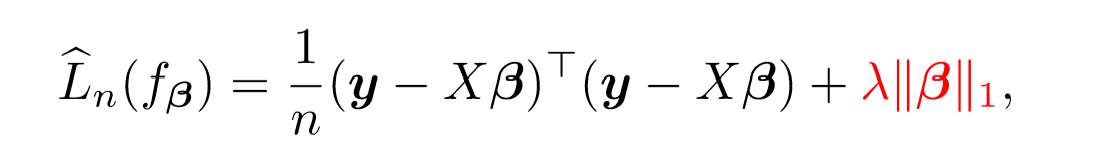
because this penalty has a kink at zero the solution can set some coefficients exactly to zero (in the simple case of uncorrelated standardised features, LASSO shrinks each OLS coefficient towards zero by a fixed amount (in scikit-learn by lambda/2) and sets it to zero if it is smaller than that), which removes features from the model then
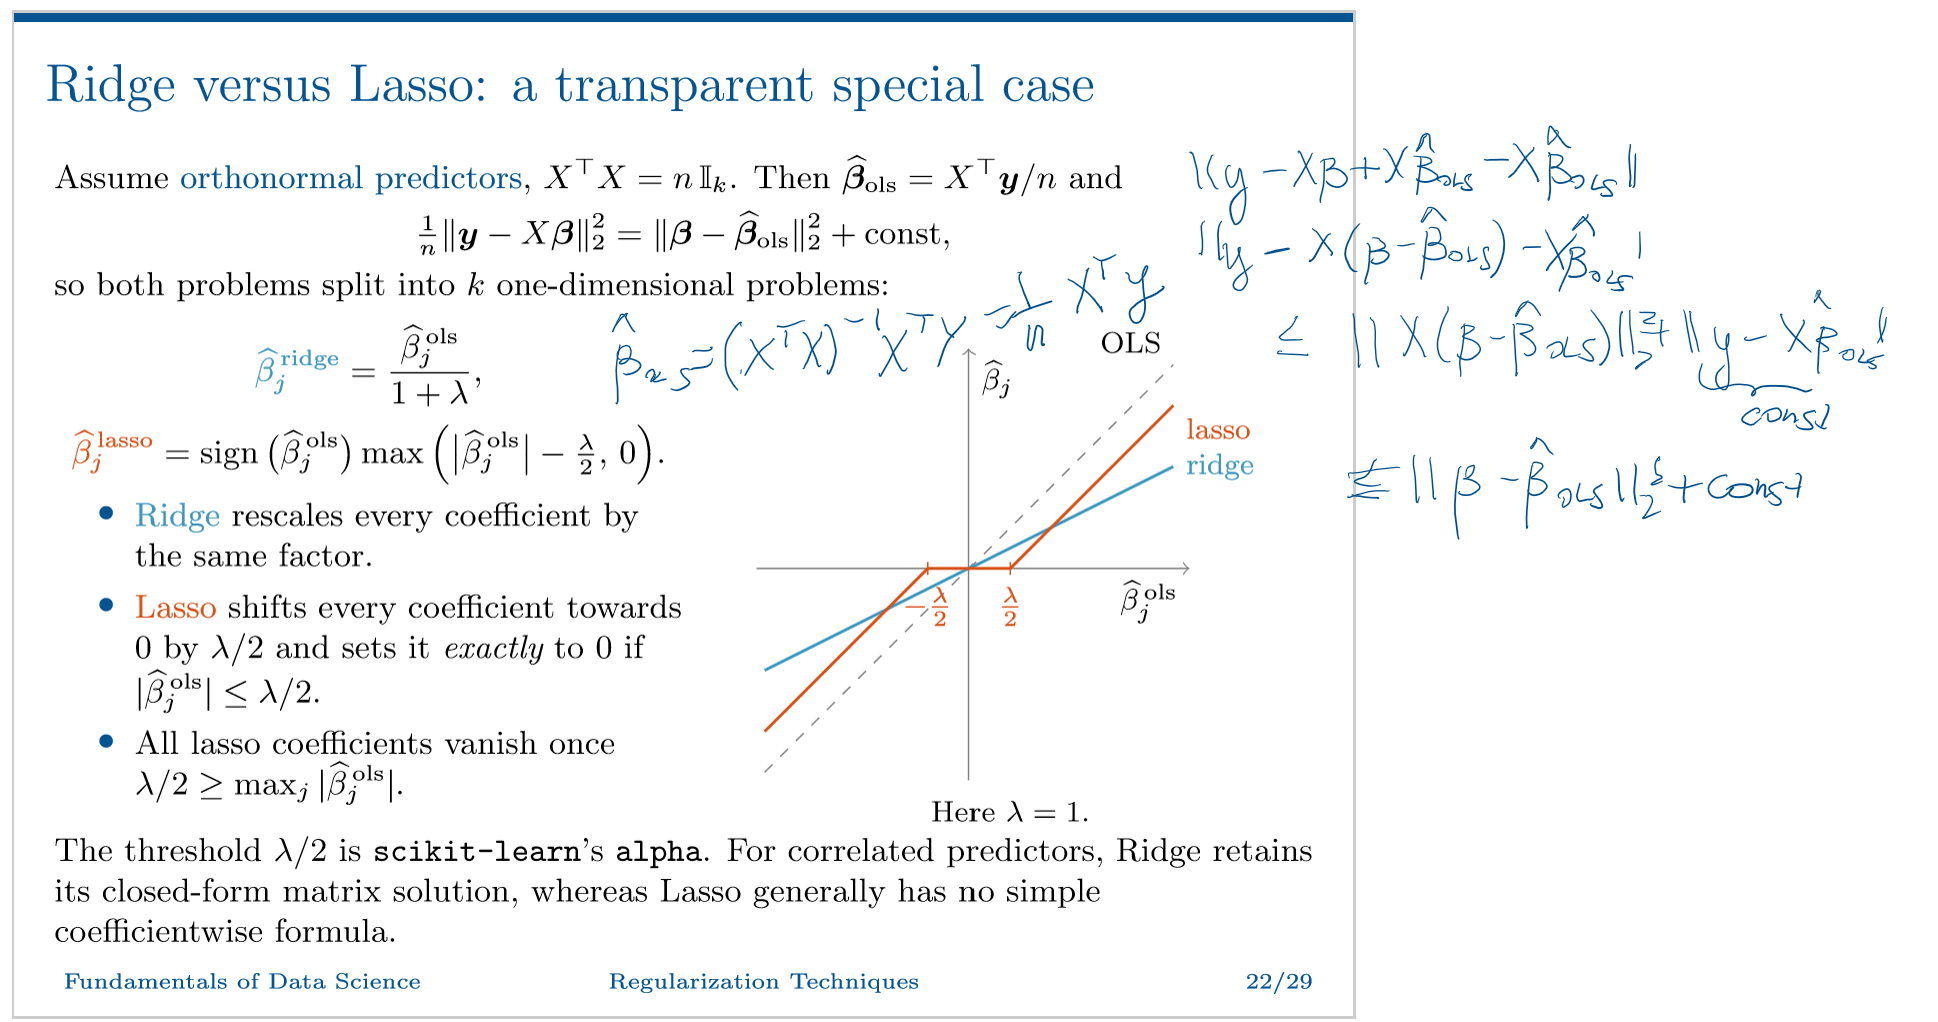
the features are scaled before fitting because the penalty treats all coefficients equally so a feature measured in large units gets a small coefficient and is barely penalised so without scaling the penalty would depend on the units and not on how useful the feature is.

In [35]:
# 2
from sklearn.linear_model import Lasso

lasso = Lasso(alpha=0.05).fit(X_train, y_train) # fit LASSO with given alpha
y_hat_lasso = lasso.predict(X_test) # predict on the test data


In [36]:
# 3
results.loc["LASSO (alpha=0.05)"] = [mean_squared_error(y_test, y_hat_lasso),
                                     mean_absolute_error(y_test, y_hat_lasso)]
display(results)


,MSE,MAE
Benchmark (the mean),2.325787,1.202816
Linear regression,1.349168,0.846731
LASSO (alpha=0.05),1.357263,0.843942


the lasso is roughly equivalent to the linear regression here. the test mse is 1.357 vs 1.349 (slightly worse) and the test mae is 0.844 vs 0.847 (slightly better), so the differences are tiny, and both models are clearly better than the benchmark (mse 2.33, mae 1.20). this does not really surprise me with 522 training stations and only 29 features the linear regression does not overfit much, so shrinking the coefficients cannot help a lot. the lasso only removes features that matter little, so the predictions stay almost the same.

In [37]:
# 4
coefs = pd.Series(lasso.coef_, index=X_train.columns) #coefficients with their feature names

# keep only the non-zero ones, sorted by absolute size
nonzero = coefs[coefs != 0].sort_values(key=abs, ascending=False)
print(nonzero)
print("Set exactly to zero:", (coefs == 0).sum(), "of", len(coefs))

platform_length_total    0.906842
Kt_Ct_Cantone_ZH         0.181818
platform_area_total      0.173542
height                  -0.124657
Kt_Ct_Cantone_GE         0.112363
Kt_Ct_Cantone_GR        -0.037318
Kt_Ct_Cantone_LU         0.036908
Kt_Ct_Cantone_TG        -0.035885
Kt_Ct_Cantone_VD        -0.027393
Kt_Ct_Cantone_BS        -0.025806
Kt_Ct_Cantone_TI        -0.021169
Kt_Ct_Cantone_SH         0.012346
Kt_Ct_Cantone_GL        -0.009654
n_platforms              0.007358
share_track_free         0.004199
dtype: float64
Set exactly to zero: 14 of 29


the lasso keeps 15 features and sets 14 of 29 exactly to zero. by far the largest coefficient belongs to platform_length_total (about 0.91), followed by the canton ZH (0.18), platform_area_total (0.17), height (-0.12, higher stations are quieter) and the canton GE (0.11). most other cantons are small or zero, n_platforms and share_track_free are almost zero (about 0.007 and 0.004) and the coordinates and the operator dummy ISB_GI_STB are set exactly to zero

this partly matches my expectations from part 1 so the size of the station is the most important predictor, as the scatterplot showed in one of the questions above. platform_length_total and platform_area_total both measure station size, so the lasso mostly keeps the length and gives the area a smaller coefficient. what i did not expect is that the coordinates are dropped, probably because the canton and the height already capture most of the location effect


---

**Before continuing: Question 11 is optional.**

Correct code, expected results and thoughtful answers to Questions 1–10 earn a **grade of 5.6**: $5.6 = 4 + 0.8 \times (6 - 4)$, or 80% of the way from a passing grade of 4 to the maximum grade of 6.

You may stop here. To aim higher, continue to Question 11 and develop a model that improves on your two baseline models. We assess technical quality, creativity and overall presentation; there is no single correct solution.

---


### Question 11 (OPTIONAL)

Develop a model that improves on your two baseline models and predicts reliably **for stations it has never seen**. Consider how an infrastructure operator might use it to plan station capacity.

How you achieve this is up to you. Some directions you may want to consider:
- **nonlinear effects**: the relationship between platform area and demand is unlikely to be linear in the raw variables;
- **interactions**: e.g. between station size and operator, or between size and region;
- **better features**: the service point register also contains the municipality — the municipal **population** is public information and could be an important predictor of how busy a station is. You are allowed to bring in such an external variable if you document the source;
- **better validation**: several stations can lie in the same municipality, and stations of the same municipality are not independent. A model validated on a random split may therefore look better than it is. Consider holding out **entire municipalities** instead of random rows when creating validation splits or folds **within the training data**. Keep the **original hold-out test set from Question 8 unchanged** for the final evaluation;
- **model choice and tuning**: cross-validation to choose `alpha` rather than fixing it at 0.05, or a different model class altogether.

Two rules apply:
1. Choose your features, model and tuning settings **using the training data only**, with a validation split or cross-validation. Questions 9 and 10 have already evaluated the baseline models on the test set; do not use those test results to guide your choices in this question. Once your final model and procedure are fixed, evaluate that model **once**, at the end of this question, on the same test set. Do not revise the model in response to that result.
2. Report the same two metrics (MSE and MAE) so that your final model is directly comparable to Questions 9 and 10.

Be explicit about what you did and why. Explain how your changes affect model performance and how you evaluated success.

We assess the soundness of your reasoning, the transparency of your approach and the clarity of your explanation.

In [38]:
# Your solution

plan
my goal in this question is a model that predicts the number of passengers well for stations it has never seen, so that an infrastructure operator could use it to plan the capacity of new or rebuilt stations. to keep the evaluation fair, i choose the features, the model and the regularization strength only with cross-validation inside the training data. the test set from question 8 stays unchanged (same rows), and i only evaluate my final model on it once, at the very end. for the same reason, i only plot training stations, so that i don't look at the test set before the end.

first, i plot the training stations on a map to see where the busy stations are. based on this, i build new features: the log of the size variables, location features that i calculate from the coordinates in the station register (number of stops nearby, distance to the next big city and to the next train station), the type of station (park & ride, tram nearby), the population of the municipality and the result of the 2014 vote on the railway infrastructure, plus one interaction between station size and urban density. since stations in the same municipality are not independent, i validate with groupkfold by municipality instead of random folds. then i compare linear regression, lasso, ridge and elastic net, choose the best one by cross-validation and finally evaluate it once on the test set.


also a disclaimer: I intensively used Claude for the coding in this session since I had a lot of ideas but not the time to write the code, as you will see it's more extensive and advanced than the code above. the ideas are still mine, I just pasted the solutions from the notebooks we used this week, told him what I want and he coded the cells for me which worked surprisingly well. I made sure to understand the code, also all comments are from me

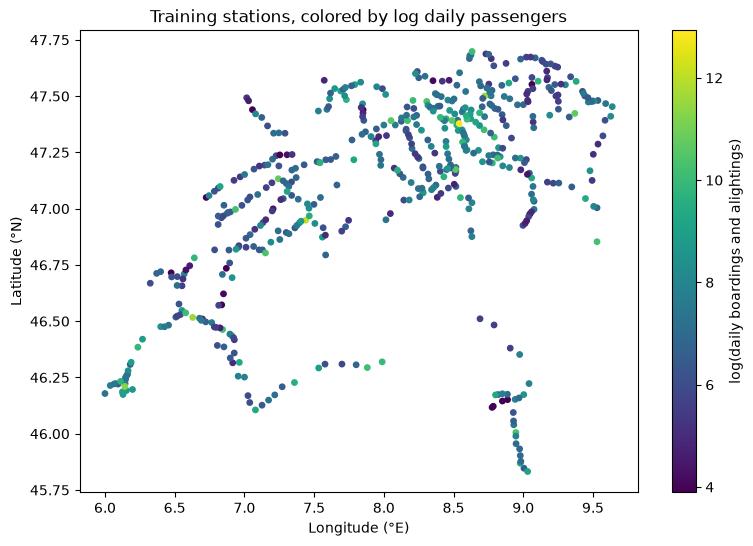

In [39]:
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.linear_model import LassoCV, Ridge, ElasticNetCV

# map of training stations only, mapped with how intensively they are used
train_stations = master.loc[X_train.index]

fig, ax = plt.subplots(figsize=(9, 6))
map_points = ax.scatter(train_stations["wgs84East"], train_stations["wgs84North"],
                        c=train_stations["y"], cmap="viridis", s=15)
fig.colorbar(map_points, ax=ax, label="log(daily boardings and alightings)")
ax.set_xlabel("Longitude (°E)")
ax.set_ylabel("Latitude (°N)")
ax.set_title("Training stations, colored by log daily passengers")
plt.show()

the map shows that the busiest training stations (bright points) are in the cities: zürich hb, bern, lausanne, winterthur and genève and the quiet stations (dark points) are small stops in rural areas and in the mountains, e.g. in ticino.

in question 10 the lasso set wgs84East and wgs84North to zero. this makes sense: in a linear model they mean "the further east (or north), the more passengers", which is not true. what matters is how close a station is to a city and how dense the area around it is. this is a nonlinear function of the coordinates. so i don't use the raw coordinates again, but i turn them into features that make sense, so

n_stops_1km: number of service points (mostly bus and tram stops) within 1 km of the station -> how urban the area is

dist_hub_km: distance to the nearest big hub (zürich hb, bern, basel sbb, genève, lausanne) -> commuter areas around the big cities

dist_next_station_km: distance to the next other train station -> dense network vs. remote stop

the station register contains all 30'000+ swiss service points, not only train stations, so i can count the bus and tram stops around each station without any extra data. for the distances i use the swiss coordinates lv95East and lv95North, which are in metres, so a distance is just pythagoras.

In [40]:
# all swiss service points (bus etc.) that are valid on the reference date
points = pd.read_csv("data/stations.csv", sep=";", encoding="utf-8-sig", low_memory=False,
                     usecols=["number", "validFrom", "validTo", "status", "isoCountryCode",
                              "meansOfTransport", "categories", "lv95East", "lv95North"])

points["validFrom"] = points["validFrom"].astype("datetime64[s]")
points["validTo"] = points["validTo"].astype("datetime64[s]")
points["number"] = points["number"].astype("string")

points = points[(points["validFrom"] <= REFERENCE_DATE) & (REFERENCE_DATE <= points["validTo"])
                & (points["status"] == "VALIDATED") & (points["isoCountryCode"] == "CH")]

trains = points[points["meansOfTransport"].str.contains("TRAIN", na=False)]       # all train stations
trams = points[points["meansOfTransport"].str.contains("TRAM|METRO", na=False)]   # all tram and metro stops
hubs = points[points["number"].isin(["8503000", "8507000", "8500010", "8501008", "8501120"])]  # ZH, BE, BS, GE, LS

# copy of master with the swiss coordinates (in metres) of each station
master11 = master.copy()
master11["lv95East"] = master11["UIC"].map(points.set_index("number")["lv95East"])
master11["lv95North"] = master11["UIC"].map(points.set_index("number")["lv95North"])

# Park & Ride: 1 if the station has the category PARK_AND_RAIL in the register else 0
master11["park_and_rail"] = (master11["UIC"].map(points.set_index("number")["categories"])
                             .str.contains("PARK_AND_RAIL", na=False).astype(int))

# distance in km from one station to many other points (Pythagoras as mentioned above)
def distances_km(east, north, other):
    return np.sqrt((other["lv95East"] - east)**2 + (other["lv95North"] - north)**2) / 1000

n_stops, dist_hub, dist_next, tram_1km = [], [], [], []
for _, row in master11.iterrows():
    n_stops.append((distances_km(row["lv95East"], row["lv95North"], points) <= 1).sum() - 1)  # -1 bcs not the station itself
    dist_hub.append(distances_km(row["lv95East"], row["lv95North"], hubs).min())
    other_trains = trains[trains["number"] != row["UIC"]]  # all train stations except the station itself
    dist_next.append(distances_km(row["lv95East"], row["lv95North"], other_trains).min())
    tram_1km.append(int((distances_km(row["lv95East"], row["lv95North"], trams) <= 1).any()))  # 1 if a tram/metro stop is within 1 km

master11["n_stops_1km"] = n_stops
master11["dist_hub_km"] = dist_hub
master11["dist_next_station_km"] = dist_next
master11["tram_1km"] = tram_1km
display(master11[["n_stops_1km", "dist_hub_km", "dist_next_station_km", "park_and_rail", "tram_1km"]].describe().round(2))

,n_stops_1km,dist_hub_km,dist_next_station_km,park_and_rail,tram_1km
count,746.00,746.00,746.00,746.00,746.00
mean,12.05,35.74,2.01,0.62,0.07
std,11.40,29.96,1.14,0.49,0.25
min,1.00,0.00,0.04,0.00,0.00
25%,4.00,17.79,1.14,0.00,0.00
50%,8.00,29.25,1.84,1.00,0.00
75%,16.00,41.98,2.67,1.00,0.00
max,77.00,174.38,6.91,1.00,1.00


In [41]:
# population of each municipality on 31.12.2024
# source: https://statistik.admin.ch/rm/asset/36073772
pop = pd.read_csv("data/population_2024.csv", skiprows=1, usecols=["Region", "Total"], encoding="latin-1")

# encoded with the help of claude: municipalities look like "......0001 Aeugst am Albis": keep only those and take the 4-digit number
pop = pop[pop["Region"].str.startswith("......", na=False)]
pop["fsoNumber"] = pop["Region"].str[6:10].astype(int).astype(str)
pop["population"] = pop["Total"].str.replace(" ", "").astype(int)

# add the population to each station via the municipality number
master11["population"] = master11["fsoNumber"].map(pop.set_index("fsoNumber")["population"])
print("Stations without population:", master11["population"].isna().sum())


Stations without population: 0


In [42]:
# yes share (%) in the vote of 9.2.2014 on the financing and expansion of the railway infrastructure
# Source: https://www.pxweb.bfs.admin.ch/pxweb/de/px-x-1703030000_101/-/px-x-1703030000_101.px/table/tableViewLayout2/
raw = pd.read_csv("data/vote_rail_2014.csv", sep="\t", header=None, encoding="latin-1")[0]
parts = raw.str.replace('"', "").str.split(";")
vote = pd.DataFrame({"region": parts.str[0], "yes_rail_2014": parts.str[-1]})  # last field = "Ja in %"

# municipalities look like the ones in the previous cell
vote = vote[vote["region"].str.startswith("......")]
vote["municipalityName"] = vote["region"].str[6:]
vote["yes_rail_2014"] = pd.to_numeric(vote["yes_rail_2014"], errors="coerce")  # "..." (no result) becomes NaN
print("Municipality names unique:", vote["municipalityName"].is_unique)

# the file has no municipality numbers so I match by name (names are unique)
master11["yes_rail_2014"] = master11["municipalityName"].map(vote.set_index("municipalityName")["yes_rail_2014"])
print("Stations without vote result:", master11["yes_rail_2014"].isna().sum())
display(master11.loc[master11["yes_rail_2014"].isna(), ["Bahnhof_Gare_Stazione", "municipalityName"]])

# fill the few missing ones with the median of the training stations
master11["yes_rail_2014"] = master11["yes_rail_2014"].fillna(master11.loc[X_train.index, "yes_rail_2014"].median())


Municipality names unique: True
Stations without vote result: 4


,Bahnhof_Gare_Stazione,municipalityName
39,Ecublens-Rue,Ecublens (FR)
114,St-Blaise CFF,Saint-Blaise
317,Bodio TI,Bodio
347,Grolley,Grolley


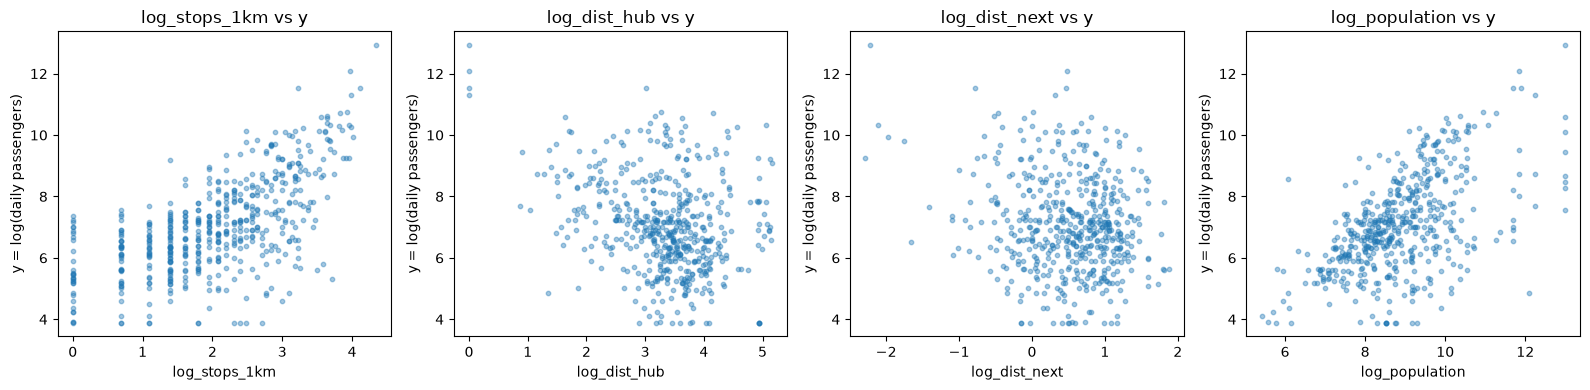

park_and_rail
0    6.487484
1    7.422998
Name: y, dtype: Float64

tram_1km
0    6.928578
1    8.821207
Name: y, dtype: Float64

Correlation yes_rail_2014 with y: 0.34


In [43]:
# log of the skewed variables (question 6: the relation is linear on a log-log scale)
master11["log_area"] = np.log(master11["platform_area_total"].astype(float))
master11["log_length"] = np.log(master11["platform_length_total"].astype(float))
master11["log_n_platforms"] = np.log(master11["n_platforms"].astype(float))
master11["log_stops_1km"] = np.log(master11["n_stops_1km"].astype(float))
master11["log_dist_hub"] = np.log1p(master11["dist_hub_km"])  # log(1 + x), because the hubs themselves have distance 0
master11["log_dist_next"] = np.log(master11["dist_next_station_km"])
master11["log_population"] = np.log(master11["population"].astype(float))

# interaction means a big station in a dense area should be even busier
master11["area_x_stops"] = master11["log_area"] * master11["log_stops_1km"]

# new features vs y and training stations only
train11 = master11.loc[X_train.index]
new_cols = ["log_stops_1km", "log_dist_hub", "log_dist_next", "log_population"]

fig, ax = plt.subplots(1, 4, figsize=(16, 4))
for i, col in enumerate(new_cols):
    ax[i].scatter(train11[col], train11["y"], alpha=0.4, s=10)
    ax[i].set_xlabel(col)
    ax[i].set_ylabel("y = log(daily passengers)")
    ax[i].set_title(f"{col} vs y")
plt.tight_layout()
plt.show()

# mean y for stations with and without Park & Ride and tram, and correlation of the vote with y (training only), look at the pics in another tab for bigger
display(train11.groupby("park_and_rail")["y"].mean())
display(train11.groupby("tram_1km")["y"].mean())
print("Correlation yes_rail_2014 with y:", round(train11["y"].astype(float).corr(train11["yes_rail_2014"]), 2))

my new features

log of the size variables (log_area, log_length, log_n_platforms): question 6 showed that the relation between platform area and passengers is linear on a log-log scale, not on the raw scale. since y is already a log, a linear model fits better with log features

location (log_stops_1km, log_dist_hub, log_dist_next): i take the log here too, because going from 5 to 10 stops is a bigger difference than going from 70 to 75.

population of the municipality (log_population): more people living in a town means more potential passengers. it uses the municipalities as of 31.12.2024, so every station gets a value.

interaction area_x_stops = log_area × log_stops_1km: a big station in a dense city should get even more passengers than a big station in the countryside.

type of station from the station register

park_and_rail (1 = the station has a park & ride): these are typical commuter stations.

tram_1km (1 = a tram or metro stop within 1 km): trams only exist in cities, so this marks city stations

attitude towards public transport: the yes share in % in the vote of 9.2.2014 on the financing and expansion of the railway infrastructure (fabi). I can imagine that a municipality that votes strongly for the railway probably uses it more.

the plots show that log_stops_1km and log_population go up with y, and log_dist_hub goes down with y (stations far away from the big cities are quieter), so these features carry information.

what i did not use:
data per canton (e.g. ga holders or population density per canton): the canton dummies already capture every effect that is the same for all stations of a canton, so such a variable would add no information to a linear model. useful extra data has to vary within a canton, like the population or the vote result of the municipality.

an interaction with the operator: in master there are only sbb (743 stations) and stb (3 stations), so there is nothing to learn. this also explains question 5: the platform register seems to cover only sbb stations, which is why 405 stations had no platform data. for the same reason i drop ISB_GI as a feature.

the raw coordinates: replaced by the location features (see above).

In [44]:
features11 = ["Kt_Ct_Cantone", "height", "share_track_free",
              "log_area", "log_length", "log_n_platforms",
              "log_stops_1km", "log_dist_hub", "log_dist_next",
              "log_population", "area_x_stops",
              "park_and_rail", "tram_1km", "yes_rail_2014"]

# same rows as in question 8
X11_train = master11.loc[X_train.index, features11]
X11_test = master11.loc[X_test.index, features11]
y11_train = master11.loc[X_train.index, "y"].astype(float)
y11_test = master11.loc[X_test.index, "y"].astype(float)
print("Same test set as in question 8:", np.allclose(y11_test, y_test.astype(float)))

# like in question 8
encoder11 = OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False)
encoder11.set_output(transform="pandas")
encoder11.fit(X11_train[["Kt_Ct_Cantone"]])

numeric11 = [col for col in features11 if col != "Kt_Ct_Cantone"]
X11_train = pd.concat([X11_train[numeric11].astype(float), encoder11.transform(X11_train[["Kt_Ct_Cantone"]])], axis=1)
X11_test = pd.concat([X11_test[numeric11].astype(float), encoder11.transform(X11_test[["Kt_Ct_Cantone"]])], axis=1)

scaler11 = StandardScaler().set_output(transform="pandas")
scaler11.fit(X11_train)
X11_train, X11_test = scaler11.transform(X11_train), scaler11.transform(X11_test)

print("X11_train:", X11_train.shape, " X11_test:", X11_test.shape)

Same test set as in question 8: True
X11_train: (522, 34)  X11_test: (224, 34)


several stations can lie in the same municipality (e.g. zürich hb, zürich oerlikon and zürich stadelhofen). they share the same population and canton have similar location features and often similar passenger numbers so they are not independent.

with normal kfold the folds are random rows. so a station from zürich can be in the validation fold while other zürich stations are in the training folds. the model has then already "seen" this municipality and the validation error looks better than it really is. but my goal is to predict stations the model has never seen e.g. a new station in a town that has no station yet. this is why kfold does not make sense here.

groupkfold keeps all stations of one municipality (fsoNumber) together: they are either all in the training folds or all in the validation fold. so every validation fold contains only municipalities the model has never seen which is exactly the situation we want to test. i use 5 folds and only the training data.

In [45]:
# five folds and all stations of one municipality stay in the same fold
groups = master11.loc[X_train.index, "fsoNumber"]
cv = list(GroupKFold(n_splits=5).split(X11_train, y11_train, groups))

# mean validation MSE over the 5 grouped folds like in 108b
def cv_mse(model, X):
    return -cross_val_score(model, X, y11_train, cv=cv, scoring="neg_mean_squared_error").mean()

# add the feature groups
feature_groups = {
    "+ A: log size": ["log_area", "log_length", "log_n_platforms"],
    "+ B: location": ["log_stops_1km", "log_dist_hub", "log_dist_next"],
    "+ C: population": ["log_population"],
    "+ D: interaction": ["area_x_stops"],
    "+ E: station type": ["park_and_rail", "tram_1km"],
    "+ F: rail vote 2014": ["yes_rail_2014"],
}

cols = ["height", "share_track_free"] + [col for col in X11_train.columns if col.startswith("Kt_")]
cv_table = {"Q8 features (old)": cv_mse(LinearRegression(), X_train)}  # the matrix from question 8
for name, extra in feature_groups.items():
    cols = cols + extra
    cv_table[name] = cv_mse(LinearRegression(), X11_train[cols])
display(pd.Series(cv_table, name="grouped CV MSE").round(3))

# four models on all new features
alphas = np.logspace(-3, 1, 100)

lasso11 = LassoCV(alphas=alphas, cv=cv).fit(X11_train, y11_train)

ridge_scores = []
for alpha in alphas:
    ridge_scores.append(cv_mse(Ridge(alpha=alpha), X11_train))
best_alpha_ridge = alphas[np.argmin(ridge_scores)]

enet11 = ElasticNetCV(alphas=alphas, l1_ratio=[0.1, 0.5, 0.9], cv=cv).fit(X11_train, y11_train)

model_table = pd.DataFrame({
    "best alpha": [None, lasso11.alpha_, best_alpha_ridge, enet11.alpha_],
    "grouped CV MSE": [cv_mse(LinearRegression(), X11_train),
                       lasso11.mse_path_.mean(axis=1).min(),
                       min(ridge_scores),
                       enet11.mse_path_.mean(axis=2).min()]},
    index=["Linear regression", "LASSO", "Ridge", "Elastic Net"])
display(model_table)
print("Elastic Net l1_ratio:", enet11.l1_ratio_)

Q8 features (old)      1.061
+ A: log size          0.786
+ B: location          0.647
+ C: population        0.638
+ D: interaction       0.583
+ E: station type      0.557
+ F: rail vote 2014    0.550
Name: grouped CV MSE, dtype: float64

,best alpha,grouped CV MSE
Linear regression,NaN,0.549929
LASSO,0.002310,0.547121
Ridge,0.151991,0.549724
Elastic Net,0.002105,0.547604


Elastic Net l1_ratio: 0.9


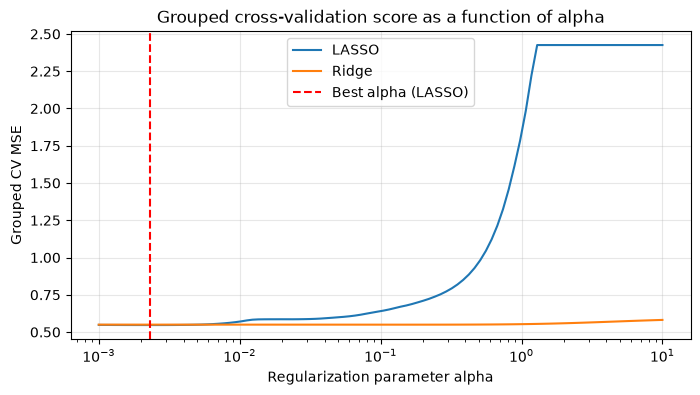

area_x_stops        2.179
log_stops_1km      -1.369
log_area            0.324
Kt_Ct_Cantone_TI   -0.210
park_and_rail       0.181
Kt_Ct_Cantone_VD   -0.161
log_population      0.134
Kt_Ct_Cantone_BS   -0.127
dtype: float64

In [46]:
fig, ax = plt.subplots(figsize=(8, 4))

# CV MSE for each alpha that was tried
ax.plot(lasso11.alphas_, lasso11.mse_path_.mean(axis=1), label="LASSO")
ax.plot(alphas, ridge_scores, label="Ridge")
ax.axvline(lasso11.alpha_, linestyle="--", color="red", label="Best alpha (LASSO)")

ax.set_xscale("log")
ax.set_xlabel("Regularization parameter alpha")
ax.set_ylabel("Grouped CV MSE")
ax.set_title("Grouped cross-validation score as a function of alpha")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

# largest LASSO coefficients
coefs11 = pd.Series(lasso11.coef_, index=X11_train.columns)
display(coefs11.sort_values(key=abs, ascending=False).head(8).round(3))

every feature group lowers the grouped cv mse: from 1.061 with the question 8 features to 0.786 with the log size features, 0.647 with the location features, 0.638 with the population, 0.583 with the interaction, 0.557 with park & ride and tram, and 0.550 with the rail vote. the biggest gains come from the log transformation and the location features, which supports my idea from the map. the station type (park & ride, tram) helps clearly as well.

the four models are almost equally good (grouped cv mse between 0.547 and 0.550). the chosen alphas are very small, so there is not much to regularize: with 522 stations and 34 features the linear model hardly overfits. elastic net chooses l1_ratio = 0.9, so it is almost a lasso anyway. i choose the lasso because it has the lowest grouped cv mse (0.547) and its alpha is chosen by cross-validation instead of being fixed at 0.05 like in question 10 but it's funny to see that actually here the model does not really matter and the biggest impact is by the data quality

the largest coefficients belong to area_x_stops, log_stops_1km and log_area. since area_x_stops is built from the other two, these three have to be read together: the positive interaction means that a dense area increases the passengers more for big stations than for small ones. park_and_rail also gets one of the largest coefficients.

,MSE,MAE
Benchmark (the mean),2.325787,1.202816
Linear regression,1.349168,0.846731
LASSO (alpha=0.05),1.357263,0.843942
"Q11: LASSO (new features, grouped CV)",0.598696,0.601091


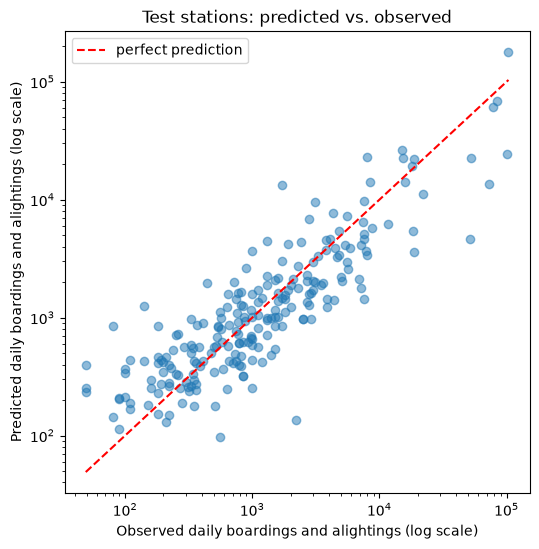

In [47]:
# LassoCV is already refitted on the whole training set with the best alpha
y_hat_11 = lasso11.predict(X11_test)

# add row to table from questions 9 and 10
results.loc["Q11: LASSO (new features, grouped CV)"] = [mean_squared_error(y11_test, y_hat_11),
                                                        mean_absolute_error(y11_test, y_hat_11)]
display(results)

# predicted versus observed daily passengers from test stations
observed = np.exp(y11_test)
predicted = np.exp(y_hat_11)

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(observed, predicted, alpha=0.5)
ax.plot([49, observed.max()], [49, observed.max()], color="red", linestyle="--", label="perfect prediction")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Observed daily boardings and alightings (log scale)")
ax.set_ylabel("Predicted daily boardings and alightings (log scale)")
ax.set_title("Test stations: predicted vs. observed")
ax.legend()
plt.show()

final evaluation

my final model reaches a test mse of 0.599 and a test mae of 0.601, compared to 1.349 and 0.847 for the linear regression from question 9 and 1.357 and 0.844 for the lasso from question 10. so the mse is more than halved, and the model is much better than the benchmark (mse 2.33, mae 1.20). the improvement comes from better features, not from a different model class: the log size features, the location features from the station register, the population, the station type and the rail vote.

the test mse (0.599) is a bit higher than the grouped cv mse (0.547). this is expected: the cv score of the chosen model is slightly too optimistic, because it won the comparison. the difference is small, so the grouped cross-validation gave a realistic picture. to be transparent: while developing this question, two earlier versions of the model (without the station type and the vote) were also evaluated on the test set (mse 0.629 and 0.649). the final feature set was chosen only with the grouped cross-validation on the training data, not because of these test results.

on the original scale, an mae of 0.601 means that a prediction is off by a factor of about e^0.60 approx. 1.8 on average (before: e^0.85 approx. 2.3)

how an infrastructure operator could use it all inputs are known before a station is built or rebuilt (platform size, location, park & ride, population and vote result of the municipality). so an operator could predict the demand for a planned station, or compare the predicted demand of an existing station with its platform capacity and flag stations where the predicted demand is much higher than what the platforms are built for. since the error is still about a factor of 1.8, i would use it as a first screening tool and not as an exact forecast (obviosly)